# KAN–PIN Framework: 1-D Burgers — Sin Benchmark

**PDE:**
$$\frac{\partial u}{\partial t} + u\,\frac{\partial u}{\partial x} = \nu\,\frac{\partial^2 u}{\partial x^2}, \quad x\in[-1,1],\; t\in[0,T]$$

**IC / BC (Raissi et al.):**
$$u(0,x) = -\sin(\pi x), \qquad u(t,-1) = u(t,1) = 0$$

No closed-form analytic solution exists for this problem.  A **fine-grid FD solution** (nx=1001, dt=0.0005) is used as pseudo-truth for
error analysis.  A **coarse FD** (nx=201) runs at the same spatial resolution
as the KAN evaluation grid for a fair side-by-side comparison.

Structure mirrors `kan_burgers_sawtooth.ipynb`.

In [2]:
import sys, os, time, copy
sys.path.insert(0, os.path.dirname(os.getcwd()))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pinns_framework import (
    PINArchitecture, PINSpatialDimension, PINLossFunction, PINTrainer,
    save_pinns, load_pinns,
    collocation_curvature,
)

torch.manual_seed(0)
np.random.seed(0)
print('torch:', torch.__version__)


torch: 2.10.0


## 1. Problem Setup

The Raissi et al. benchmark uses $\nu = 0.01/\pi \approx 0.00318$, which is
small enough for a sharp (but smooth) solution to develop by $t \approx 0.5$.
We stop at $T=0.4$ to stay safely before shock formation while still
capturing interesting nonlinear dynamics.

**Reference:** fine-grid FD with nx = 1001 and dt = 0.0005 is treated as
pseudo-truth.  CFL and diffusion stability are verified below.

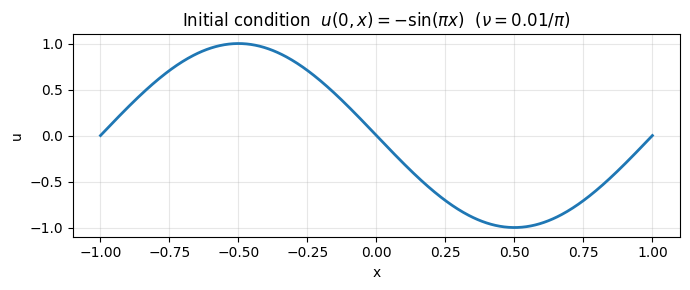

In [3]:
NU     = 0.01 / np.pi   # ≈ 0.003183
X0, XF = -1.0, 1.0
T_END  = 0.4
DT     = 0.1
NT     = int(T_END / DT)  # 4 PDE steps
times  = [k * DT for k in range(NT + 1)]

# ── Plot the IC ──────────────────────────────────────────────────────────
x_plot = np.linspace(X0, XF, 500)
u_ic_plot = -np.sin(np.pi * x_plot)

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(x_plot, u_ic_plot, lw=2)
ax.set_xlabel('x'); ax.set_ylabel('u')
ax.set_title(r'Initial condition  $u(0,x) = -\sin(\pi x)$  ($\nu = 0.01/\pi$)')
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()


## 2. Finite Difference Reference

**Scheme** — explicit upwind advection + central diffusion, **Dirichlet** BC:
$$u_i^{n+1} = u_i^n
  - u_i^n\frac{\Delta t}{\Delta x}(u_i^n - u_{i-1}^n)
  + \nu\frac{\Delta t}{\Delta x^2}(u_{i+1}^n - 2u_i^n + u_{i-1}^n)$$
with $u_0 = u_N = 0$ enforced after every step.

Two grids are used:
- **Fine FD** (nx=1001, dt=0.0005): pseudo-truth for error metrics.
- **Coarse FD** (nx=201, dt=0.002): same spatial resolution as KAN evaluation, for fair comparison.

In [4]:
# ── Common FD step (Dirichlet BCs) ──────────────────────────────────────
def fd_step_dirichlet(u, dx, dt, nu):
    u_l = np.concatenate([[0.0], u[:-1]])   # u_{i-1}, left ghost = 0
    u_r = np.concatenate([u[1:],  [0.0]])   # u_{i+1}, right ghost = 0
    u_new = u - dt * u * (u - u_l) / dx + dt * nu * (u_r - 2*u + u_l) / dx**2
    u_new[0] = u_new[-1] = 0.0             # enforce Dirichlet
    return u_new

def fd_stability(u0, dx, dt, nu, label=''):
    CFL = float(np.max(np.abs(u0))) * dt / dx
    r   = nu * dt / dx**2
    ok_cfl  = CFL < 1.0
    ok_diff = r   < 0.5
    print(f'{label}  dx={dx:.5f}  dt={dt}')
    print(f'  CFL = {CFL:.4f}  (< 1.0)  {"OK" if ok_cfl  else "VIOLATED"}')
    print(f'  r   = {r:.4f}  (< 0.5)  {"OK" if ok_diff else "VIOLATED"}')

u0_np = -np.sin(np.pi * np.linspace(X0, XF, 3))  # just for stability check
print('=== Stability reports ===')
fd_stability(u0_np, 2/1000, 0.0005, NU, label='Fine  FD (nx=1001, dt=0.0005):')
fd_stability(u0_np, 2/200,  0.002,  NU, label='Coarse FD (nx=201,  dt=0.002):')


=== Stability reports ===
Fine  FD (nx=1001, dt=0.0005):  dx=0.00200  dt=0.0005
  CFL = 0.0000  (< 1.0)  OK
  r   = 0.3979  (< 0.5)  OK
Coarse FD (nx=201,  dt=0.002):  dx=0.01000  dt=0.002
  CFL = 0.0000  (< 1.0)  OK
  r   = 0.0637  (< 0.5)  OK


In [5]:
# ── Run fine FD (pseudo-truth) ───────────────────────────────────────────
NX_FINE  = 1001
DT_FINE  = 0.0005
x_fine   = np.linspace(X0, XF, NX_FINE)
dx_fine  = x_fine[1] - x_fine[0]

t_ffd_start = time.perf_counter()
fine_sols = {0.0: -np.sin(np.pi * x_fine)}
u_ffd = fine_sols[0.0].copy()
t_ffd_out = set(times[1:])
t_cur = 0.0
while t_cur < T_END - 1e-10:
    u_ffd = fd_step_dirichlet(u_ffd, dx_fine, DT_FINE, NU)
    t_cur = round(t_cur + DT_FINE, 8)
    if any(abs(t_cur - t_out) < 1e-8 for t_out in t_ffd_out):
        fine_sols[round(t_cur, 4)] = u_ffd.copy()
t_ffd = time.perf_counter() - t_ffd_start

# ── Run coarse FD ────────────────────────────────────────────────────────
NX_COARSE = 201
DT_COARSE = 0.002
x_cmp     = np.linspace(X0, XF, NX_COARSE)   # shared evaluation grid
dx_cmp    = x_cmp[1] - x_cmp[0]

t_cfd_start = time.perf_counter()
coarse_sols = {0.0: -np.sin(np.pi * x_cmp)}
u_cfd = coarse_sols[0.0].copy()
t_cur = 0.0
t_cfd_out = set(times[1:])
while t_cur < T_END - 1e-10:
    u_cfd = fd_step_dirichlet(u_cfd, dx_cmp, DT_COARSE, NU)
    t_cur = round(t_cur + DT_COARSE, 8)
    if any(abs(t_cur - t_out) < 1e-8 for t_out in t_cfd_out):
        coarse_sols[round(t_cur, 4)] = u_cfd.copy()
t_cfd = time.perf_counter() - t_cfd_start

print(f'Fine FD   wall time: {t_ffd*1e3:.1f} ms  ({NX_FINE} pts, dt={DT_FINE})')
print(f'Coarse FD wall time: {t_cfd*1e3:.1f} ms  ({NX_COARSE} pts, dt={DT_COARSE})')
print(f'Fine FD output times: {sorted(fine_sols.keys())}')


Fine FD   wall time: 22.5 ms  (1001 pts, dt=0.0005)
Coarse FD wall time: 3.3 ms  (201 pts, dt=0.002)
Fine FD output times: [0.0, 0.1, 0.2, 0.3, 0.4]


/var/folders/wy/ljbyn3qd58nggnt6rcf6d5vr0000gp/T/ipykernel_4903/1183051971.py:5: RuntimeWarning: overflow encountered in multiply
  u_new = u - dt * u * (u - u_l) / dx + dt * nu * (u_r - 2*u + u_l) / dx**2
/var/folders/wy/ljbyn3qd58nggnt6rcf6d5vr0000gp/T/ipykernel_4903/1183051971.py:5: RuntimeWarning: invalid value encountered in subtract
  u_new = u - dt * u * (u - u_l) / dx + dt * nu * (u_r - 2*u + u_l) / dx**2
/var/folders/wy/ljbyn3qd58nggnt6rcf6d5vr0000gp/T/ipykernel_4903/1183051971.py:5: RuntimeWarning: invalid value encountered in add
  u_new = u - dt * u * (u - u_l) / dx + dt * nu * (u_r - 2*u + u_l) / dx**2


## 3. KAN Setup

Architecture `(1, 8, 1)`: 8 hidden neurons → 16 learnable activation functions,
small enough to visualize every edge.

Collocation: `collocation_curvature` — concentrates points where $|\partial^2 u/\partial x^2|$ is largest,
helping the KAN resolve the steepening region near $x=0$.

In [6]:
net = PINArchitecture(
    arch='KAN',
    params_arch={'layers': (1, 8, 1), 'grid_size': 5, 'spline_order': 3},
)
print(net)

x_dim = PINSpatialDimension('x', domain=(X0, XF), n_colloc=150)

def burgers_residual(u, u_prev, x, dt, nu):
    du_dx  = torch.autograd.grad(u.sum(),     x, create_graph=True)[0]
    du_dxx = torch.autograd.grad(du_dx.sum(), x, create_graph=True)[0]
    return (u - u_prev) / dt + u * du_dx - nu * du_dxx

loss_fn = PINLossFunction([x_dim], burgers_residual)

trainer = PINTrainer(
    net            = net,
    scheme         = 'TD-PINNS',
    loss_fn        = loss_fn,
    spatial_dims   = [x_dim],
    epochs         = 8000,
    dt             = DT,
    lr             = 1e-2,
    tolerance      = 1e-4,
    ic_weight      = 15.0,
    bc_weight      = 10.0,
    pde_weight     = 1.0,
    collocation_fn = collocation_curvature,
    verbose        = True,
    log_every      = 2000,
)
print(f'device: {trainer.device}')


checkpoint directory created: ./model
saving model version 0.0
KANNet(
  (net): MultKAN(
    (act_fun): ModuleList(
      (0-1): 2 x KANLayer(
        (base_fun): SiLU()
      )
    )
    (base_fun): SiLU()
    (symbolic_fun): ModuleList(
      (0-1): 2 x Symbolic_KANLayer()
    )
  )
)
device: mps


## 4. Initial and Boundary Conditions

IC: u(0, x) = −sin(πx) sampled on a fine grid.  
BC: u(t, −1) = u(t, 1) = 0 (homogeneous Dirichlet, exact throughout).

In [7]:
x_ic_np = np.linspace(X0, XF, 201)
u_ic_np = -np.sin(np.pi * x_ic_np)

x_ic = torch.tensor(x_ic_np, dtype=torch.float32).unsqueeze(1)
u_ic = torch.tensor(u_ic_np, dtype=torch.float32).unsqueeze(1)

x_bc = torch.tensor([[X0], [XF]])
u_bc = torch.zeros(2, 1)

print(f'IC range: [{u_ic.min():.4f}, {u_ic.max():.4f}]')
print(f'BC: u(t, {X0}) = u(t, {XF}) = 0.0')


IC range: [-1.0000, 1.0000]
BC: u(t, -1.0) = u(t, 1.0) = 0.0


## 5. Train

`trainer.fit` always returns `list[nn.Module]` — index 0 = IC network, 1…NT = PDE steps.

In [8]:
t_kan_start = time.perf_counter()

trained_nets = trainer.fit(
    x_ic=x_ic, u_ic=u_ic,
    x_bc=x_bc, u_bc=u_bc,
    T=T_END,
    nu=NU,
)

t_kan = time.perf_counter() - t_kan_start
print(f'\nKAN   wall time: {t_kan:.1f} s  ({len(trained_nets)-1} PDE steps)')
print(f'Fine FD wall time: {t_ffd*1e3:.1f} ms')
print(f'Speed ratio: {t_kan/t_ffd:,.0f}× slower than fine FD')


=== TD-PINNs | step 0 — initial condition ===
  [step 0 / IC] converged at epoch 723 | loss 9.9986e-05
=== TD-PINNs | step 1/4  (t = 0.1) ===
  [step 1] epoch  2000 | loss 1.4833e-03
  [step 1] epoch  4000 | loss 1.2607e-03
  [step 1] epoch  6000 | loss 3.3841e-04
  [step 1] epoch  8000 | loss 2.3640e-04
=== TD-PINNs | step 2/4  (t = 0.2) ===
  [step 2] epoch  2000 | loss 1.6887e-03
  [step 2] epoch  4000 | loss 4.2480e-04
  [step 2] epoch  6000 | loss 7.9572e-04
  [step 2] epoch  8000 | loss 5.4148e-04
=== TD-PINNs | step 3/4  (t = 0.3) ===
  [step 3] epoch  2000 | loss 1.4286e-02
  [step 3] epoch  4000 | loss 9.5266e-03
  [step 3] epoch  6000 | loss 7.4098e-03
  [step 3] epoch  8000 | loss 9.1771e-03
=== TD-PINNs | step 4/4  (t = 0.4) ===
  [step 4] epoch  2000 | loss 6.9759e-02
  [step 4] epoch  4000 | loss 3.6900e-02
  [step 4] epoch  6000 | loss 3.3825e-02
  [step 4] epoch  8000 | loss 5.3946e-02

KAN   wall time: 2271.8 s  (4 PDE steps)
Fine FD wall time: 22.5 ms
Speed ratio: 100

## 6. Solution Comparison — KAN vs FD vs Fine-FD Reference

In [9]:
# ── Evaluate KAN on x_cmp ────────────────────────────────────────────────
dev = trainer.device
x_t = torch.tensor(x_cmp, dtype=torch.float32).unsqueeze(1).to(dev)

kan_sols = {}
for k, net_k in enumerate(trained_nets):
    net_k.eval()
    with torch.no_grad():
        kan_sols[times[k]] = net_k(x_t).cpu().numpy().ravel()

# ── Interpolate fine FD to x_cmp for comparison ──────────────────────────
fine_on_cmp = {}
for t in times:
    fine_on_cmp[t] = np.interp(x_cmp, x_fine, fine_sols[t])


KeyError: 0.30000000000000004

In [ ]:
ncols = NT + 1
fig, axes = plt.subplots(2, ncols, figsize=(4.5 * ncols, 6),
                          gridspec_kw={'height_ratios': [2, 1]})

for k, t in enumerate(times):
    u_ref  = fine_on_cmp[t]
    u_kan  = kan_sols[t]
    u_cfd  = coarse_sols[t]

    ax = axes[0, k]
    ax.plot(x_cmp, u_ref,  'k-',   lw=1.8,  label='Fine FD (ref)')
    ax.plot(x_cmp, u_kan,  'b--',  lw=1.5,  label='KAN')
    ax.plot(x_cmp, u_cfd,  'r:',   lw=1.5,  label='Coarse FD')
    ax.set_title(f't = {t:.1f}', fontsize=10)
    ax.set_xlabel('x'); ax.set_ylabel('u')
    ax.grid(alpha=0.25)
    if k == 0:
        ax.legend(fontsize=8)

    # Pointwise error
    ax_e = axes[1, k]
    ax_e.plot(x_cmp, u_kan - u_ref, 'b-',  lw=1.2, label='KAN')
    ax_e.plot(x_cmp, u_cfd - u_ref, 'r--', lw=1.2, label='Coarse FD')
    ax_e.axhline(0, color='gray', lw=0.5)
    ax_e.set_xlabel('x'); ax_e.set_ylabel('error')
    ax_e.grid(alpha=0.25)
    if k == 0:
        ax_e.legend(fontsize=8)

fig.suptitle('Solution and pointwise error vs fine-FD reference', fontsize=12)
plt.tight_layout(); plt.show()


## 7. Error Analysis — L1, L2, L∞  (vs Fine-FD Reference)

Since no analytic solution exists, errors are computed relative to the
fine-grid FD pseudo-truth (nx=1001, dt=0.0005).

In [ ]:
def error_row(u_pred, u_ref, x, label):
    diff  = np.abs(u_pred - u_ref)
    L1    = np.trapz(diff,        x)
    L2    = np.sqrt(np.trapz(diff**2, x))
    Linf  = diff.max()
    rL2   = L2 / (np.sqrt(np.trapz(u_ref**2, x)) + 1e-12)
    mass  = np.trapz(u_pred,    x)
    energy= np.trapz(u_pred**2, x)
    return {f'{label}_L1':L1, f'{label}_L2':L2,
            f'{label}_Linf':Linf, f'{label}_rel_L2':rL2,
            f'{label}_mass':mass, f'{label}_energy':energy}

rows = []
for t in times:
    u_ref = fine_on_cmp[t]
    row   = {'t': t}
    row.update(error_row(kan_sols[t],    u_ref, x_cmp, 'KAN'))
    row.update(error_row(coarse_sols[t], u_ref, x_cmp, 'CoarseFD'))
    row['ref_mass']   = np.trapz(u_ref,    x_cmp)
    row['ref_energy'] = np.trapz(u_ref**2, x_cmp)
    rows.append(row)

df = pd.DataFrame(rows).set_index('t')

pd.set_option('display.float_format', '{:.6f}'.format)
print('=== Per-step errors vs fine-FD reference ===')
print(df[['KAN_L1','CoarseFD_L1',
          'KAN_L2','CoarseFD_L2',
          'KAN_Linf','CoarseFD_Linf',
          'KAN_rel_L2','CoarseFD_rel_L2']].to_string())

print('\n=== Summary ===')
summary = pd.DataFrame({
    'metric': ['mean L1','max L1','mean L2','max L2','mean Linf','max Linf',
               'mean rel_L2','mass max err','energy at T'],
    'KAN': [
        df['KAN_L1'].mean(),       df['KAN_L1'].max(),
        df['KAN_L2'].mean(),       df['KAN_L2'].max(),
        df['KAN_Linf'].mean(),     df['KAN_Linf'].max(),
        df['KAN_rel_L2'].mean(),
        (df['KAN_mass'] - df['ref_mass']).abs().max(),
        df['KAN_energy'].iloc[-1],
    ],
    'Coarse FD': [
        df['CoarseFD_L1'].mean(),  df['CoarseFD_L1'].max(),
        df['CoarseFD_L2'].mean(),  df['CoarseFD_L2'].max(),
        df['CoarseFD_Linf'].mean(),df['CoarseFD_Linf'].max(),
        df['CoarseFD_rel_L2'].mean(),
        (df['CoarseFD_mass'] - df['ref_mass']).abs().max(),
        df['CoarseFD_energy'].iloc[-1],
    ],
}).set_index('metric')
print(summary.to_string())


In [ ]:
t_plot = times[1:]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (key, label) in zip(axes,
        [('L1','L₁'), ('L2','L₂'), ('Linf','L∞')]):
    ax.semilogy(t_plot, df.loc[t_plot, f'KAN_{key}'],
                'b-o', lw=1.5, ms=5, label='KAN')
    ax.semilogy(t_plot, df.loc[t_plot, f'CoarseFD_{key}'],
                'r--s', lw=1.5, ms=5, label='Coarse FD')
    ax.set_xlabel('t'); ax.set_ylabel(f'{label} error (vs fine FD)')
    ax.set_title(f'{label} error evolution')
    ax.legend(); ax.grid(True, which='both', alpha=0.3)
plt.suptitle('Error evolution vs fine-FD reference', fontsize=12)
plt.tight_layout(); plt.show()


## 8. Conservation & Energy Dissipation

For Burgers with zero Dirichlet BCs, mass is **not** conserved in general
(the domain is not periodic).  Energy $E = \int u^2\,dx$ dissipates:
$$\frac{dE}{dt} = -2\nu\int\!\left(\frac{\partial u}{\partial x}\right)^2 dx \le 0$$

Comparing KAN and coarse-FD against the fine-FD reference tracks how well
each method preserves the dissipative structure of the PDE.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.plot(times, df['ref_mass'],         'k-',  lw=2,   label='Fine FD (ref)')
ax.plot(times, df['KAN_mass'],         'b-o', lw=1.5, ms=5, label='KAN')
ax.plot(times, df['CoarseFD_mass'],    'r--s',lw=1.5, ms=5, label='Coarse FD')
ax.set_xlabel('t'); ax.set_ylabel(r'$\int u\,dx$')
ax.set_title('Mass'); ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(times, df['ref_energy'],       'k-',  lw=2,   label='Fine FD (ref)')
ax.plot(times, df['KAN_energy'],       'b-o', lw=1.5, ms=5, label='KAN')
ax.plot(times, df['CoarseFD_energy'],  'r--s',lw=1.5, ms=5, label='Coarse FD')
ax.set_xlabel('t'); ax.set_ylabel(r'$\int u^2\,dx$')
ax.set_title('Energy dissipation  ($dE/dt \leq 0$)')
ax.legend(); ax.grid(alpha=0.3)

plt.suptitle('Conservation diagnostics', fontsize=12)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, key, title in [
    (axes[0], 'mass',   'Mass error vs fine FD'),
    (axes[1], 'energy', 'Energy error vs fine FD'),
]:
    ref_col = 'ref_mass' if key == 'mass' else 'ref_energy'
    ax.semilogy(times, (df[f'KAN_{key}']      - df[ref_col]).abs(),
               'b-o', lw=1.5, ms=5, label='KAN')
    ax.semilogy(times, (df[f'CoarseFD_{key}'] - df[ref_col]).abs(),
               'r--s', lw=1.5, ms=5, label='Coarse FD')
    ax.set_xlabel('t'); ax.set_title(title)
    ax.legend(); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()


## 9. KAN Graph Visualization

Each box on an edge shows the **learned spline activation function**.
Edge thickness encodes importance (from pykan's `attribute()`).

`_kan_cpu` deep-copies the inner model to CPU and repopulates all internal
activation caches — avoids MPS/CUDA device mismatches in every pykan call.

In [ ]:
def _kan_cpu(kan_net, x_1d):
    model = copy.deepcopy(kan_net.net).cpu()
    x_cpu = x_1d.detach().cpu().reshape(-1, 1)
    with torch.no_grad():
        model(x_cpu)
    model.get_act(x_cpu)
    return model, x_cpu


def plot_kan_step(trained_nets, step, x_domain, dt,
                  n_vis=300, prune=False, node_th=1e-2, edge_th=1e-2, beta=3):
    lo, hi = x_domain
    x_vis  = torch.linspace(lo, hi, n_vis).unsqueeze(1)
    kan, x_cpu = _kan_cpu(trained_nets[step], x_vis)

    tag = ''
    if prune:
        try:
            kan = kan.prune(node_th=node_th, edge_th=edge_th)
            with torch.no_grad():
                kan(x_cpu)
            kan.get_act(x_cpu)
            tag = ' [pruned]'
        except Exception as exc:
            print(f'  step {step}: pruning skipped — {exc}')
            tag = ' [prune failed — unpruned]'

    kan.plot(beta=beta, in_vars=['x'], out_vars=['u'])
    plt.suptitle(f'KAN  step {step}   t = {step * dt:.1f}{tag}', fontsize=11, y=1.02)
    plt.tight_layout(); plt.show()
    return kan


In [ ]:
x_dom = (X0, XF)
show  = list(range(NT + 1))   # all steps: 0, 1, 2, 3, 4
for step in show:
    plot_kan_step(trained_nets, step, x_dom, DT, prune=False)


In [ ]:
# Pruned KAN — dominant pathways
for step in [1, NT]:
    plot_kan_step(trained_nets, step, x_dom, DT,
                  prune=True, node_th=1e-2, edge_th=1e-2)


## 10. KAN Activation Functions — Learned Modes

For a `(1, K, 1)` KAN the final prediction decomposes as:
$$u(x) = \sum_{j=1}^{K} \varphi_{1,j}\!\bigl(\varphi_{0,j}(x)\bigr)$$

- **Layer 0** — $\varphi_{0,j}(x)$: $K$ learned *feature extractors* from the spatial coordinate.
- **Layer 1** — $\varphi_{1,j}(h_j)$: $K$ learned *output weights*, one per feature.

Unlike Fourier modes (fixed sinusoids), these adapt directly to the PDE solution.

In [ ]:
def plot_kan_modes(trained_nets, step, x_domain, dt, n_vis=400):
    """
    Plot all activation functions for every layer of a KAN of any depth.

    Layer 0      : K1 functions  φ_{0,j}(x)         — input features
    Layer 1..L-2 : Ki×K_{i+1} functions              — intermediate transforms
    Layer L-1    : K_{L-1} functions                 — output aggregators
    """
    lo, hi = x_domain
    x_vis  = torch.linspace(lo, hi, n_vis).unsqueeze(1)
    kan, x_cpu = _kan_cpu(trained_nets[step], x_vis)
    x_np = x_cpu.squeeze().numpy()

    try:
        posts = [p.detach().numpy() for p in kan.spline_postacts]
    except Exception as e:
        print(f'Cannot extract postacts: {e}'); return

    n_layers = len(posts)

    for l, post in enumerate(posts):
        # post shape: (N, n_out, n_in) for layer l
        n_out, n_in = post.shape[1], post.shape[2]
        n_edges = n_out * n_in
        cols = min(n_edges, 8)
        rows = (n_edges + cols - 1) // cols
        fig, axes = plt.subplots(rows, cols,
                                  figsize=(2.2 * cols, 2.8 * rows),
                                  squeeze=False)
        colors = plt.cm.tab10(np.linspace(0, 1, n_in))

        edge = 0
        for j in range(n_in):
            for k in range(n_out):
                ax = axes[edge // cols][edge % cols]
                # x-axis: input to this edge
                if l == 0:
                    h_in = x_np                               # layer 0 input = x
                elif kan.acts and len(kan.acts) > l:
                    h_in_t = kan.acts[l]
                    h_in = (h_in_t[:, j].detach().numpy()
                            if h_in_t.dim() > 1 else h_in_t.detach().numpy())
                else:
                    h_in = np.arange(len(post[:, k, j]))

                y_vals = post[:, k, j]
                idx    = np.argsort(h_in)
                ax.plot(h_in[idx], y_vals[idx], color=colors[j % 10], lw=1.4)

                in_label  = 'x' if l == 0 else f'$h_{{{l},{j+1}}}$'
                out_label = f'$h_{{{l+1},{k+1}}}$' if l < n_layers-1 else 'u'
                ax.set_title(f'$\\varphi_{{{l},{j+1}\\to {k+1}}}$  '
                             f'({in_label}→{out_label})', fontsize=8)
                ax.tick_params(labelsize=6)
                ax.grid(alpha=0.3)
                edge += 1

        for ax in axes.flatten()[edge:]:
            ax.set_visible(False)

        plt.suptitle(
            f'KAN layer {l} activation functions — '
            f'step {step}  (t = {step * dt:.3f})',
            fontsize=10)
        plt.tight_layout()
        plt.show()


for step in [0, NT // 2, NT]:
    plot_kan_modes(trained_nets, step, x_dom, DT)


### Mode evolution across time steps

Overlay layer-0 activations $\varphi_{0,j}(x)$ for all steps (color = time).
Shows how each basis function adapts as the solution steepens toward $x=0$.

In [ ]:
n_vis_ev = 400
x_vis_ev = torch.linspace(X0, XF, n_vis_ev).unsqueeze(1)
x_np_ev  = x_vis_ev.squeeze().numpy()

all_post0 = {}; K = None
for step in range(len(trained_nets)):
    try:
        kan, _ = _kan_cpu(trained_nets[step], x_vis_ev)
        p0 = kan.spline_postacts[0].detach().numpy()
        all_post0[step] = p0[:, :, 0]
        K = p0.shape[1]
    except Exception:
        pass

if K:
    cols = max(K // 2, 1)
    rows = (K + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(2.8 * cols, 3 * rows))
    axes = np.array(axes).flatten()
    cmap_t = plt.cm.viridis

    for j in range(K):
        ax = axes[j]
        for step, p0 in all_post0.items():
            ax.plot(x_np_ev, p0[:, j],
                    color=cmap_t(step / max(len(trained_nets)-1, 1)),
                    lw=0.9, alpha=0.85)
        ax.set_title(f'$\\varphi_{{0,{j+1}}}$ over time', fontsize=9)
        ax.tick_params(labelsize=7); ax.grid(alpha=0.25)

    for ax in axes[K:]:
        ax.set_visible(False)

    sm = plt.cm.ScalarMappable(cmap=cmap_t,
                                norm=plt.Normalize(vmin=0, vmax=T_END))
    fig.colorbar(sm, ax=axes[:K], label='t', shrink=0.7)
    plt.suptitle('Layer-0 activation evolution  (color = time)', fontsize=11)
    plt.tight_layout(); plt.show()


## 11. Symbolic Interpretation (`auto_symbolic`)

pykan fits each learned spline to a symbolic formula from a library.
For the Burgers equation, edges carrying derivative-like operators may
resolve to polynomials or trigonometric functions.

> **Note:** `auto_symbolic` can take 1–2 minutes.

In [ ]:
SYMB_LIB = ['x', 'x^2', 'x^3', 'x^4', 'sin', 'cos', 'exp', 'log', 'tanh', 'abs']

def symbolic_summary(trained_nets, step, x_domain, dt, lib=SYMB_LIB):
    lo, hi = x_domain
    x_vis  = torch.linspace(lo, hi, 300).unsqueeze(1)
    kan, x_cpu = _kan_cpu(trained_nets[step], x_vis)
    try:
        kan.auto_symbolic(lib=lib)
        print(f'\n--- Step {step}  (t = {step * dt:.1f}) ---')
        kan.print_node_scores()
    except Exception as e:
        print(f'auto_symbolic failed at step {step}: {e}')
    return kan

kan_sym = symbolic_summary(trained_nets, NT, x_dom, DT)


## 12. KAN vs Finite Differences — Conceptual Comparison

| Aspect | Coarse FD | KAN (TD-PIN) |
|---|---|---|
| Spatial representation | grid values $u_i$ | continuous function $u(x)$ |
| Discretization error | $\mathcal{O}(\Delta x)$ upwind, $\mathcal{O}(\Delta x^2)$ diffusion | none — mesh-free |
| Stencil | fixed 3-point | learned adaptive splines |
| BC enforcement | exact by construction | penalised loss term |
| Nonlinearity | $u\,(u - u_{i-1})/\Delta x$ — fixed | absorbed into splines implicitly |
| Cost per step | $\mathcal{O}(N)$ FLOPS | gradient descent (many epochs) |

The update function $\Delta u = u^{n+1} - u^n$ reveals where each method
places its correction — and how well it matches the fine-FD reference.

In [ ]:
ncols = NT
fig, axes = plt.subplots(2, ncols, figsize=(4 * ncols, 6),
                          gridspec_kw={'height_ratios': [2, 1]})

for k in range(1, NT + 1):
    t_prev, t_curr = times[k-1], times[k]
    du_kan = kan_sols[t_curr]      - kan_sols[t_prev]
    du_cfd = coarse_sols[t_curr]   - coarse_sols[t_prev]
    du_ref = fine_on_cmp[t_curr]   - fine_on_cmp[t_prev]

    ax = axes[0, k-1]
    ax.plot(x_cmp, du_ref,  'k-',   lw=1.8, label='Fine FD Δu')
    ax.plot(x_cmp, du_kan,  'b--',  lw=1.4, label='KAN Δu')
    ax.plot(x_cmp, du_cfd,  'r:',   lw=1.4, label='Coarse FD Δu')
    ax.axhline(0, color='gray', lw=0.5)
    ax.set_title(f'step {k}  →  t={t_curr:.1f}', fontsize=10)
    ax.set_xlabel('x'); ax.grid(alpha=0.25)
    if k == 1:
        ax.set_ylabel('Δu'); ax.legend(fontsize=8)

    ax_e = axes[1, k-1]
    ax_e.plot(x_cmp, du_kan - du_ref, 'b-',  lw=1.2, label='KAN')
    ax_e.plot(x_cmp, du_cfd - du_ref, 'r--', lw=1.2, label='Coarse FD')
    ax_e.axhline(0, color='gray', lw=0.5)
    ax_e.set_xlabel('x'); ax_e.grid(alpha=0.25)
    if k == 1:
        ax_e.set_ylabel('Δu error'); ax_e.legend(fontsize=8)

fig.suptitle('Time-step update Δu and its error vs fine-FD reference', fontsize=12)
plt.tight_layout(); plt.show()


## 13. Save & Load

In [ ]:
SAVE_PATH   = 'kan_burgers_sin.pt'
ARCH        = 'KAN'
PARAMS_ARCH = {'layers': (1, 8, 1), 'grid_size': 5, 'spline_order': 3}

save_pinns(trained_nets, trainer, ARCH, PARAMS_ARCH, SAVE_PATH)

loaded = load_pinns(SAVE_PATH)
x_chk  = torch.linspace(X0, XF, 5).unsqueeze(1).to(dev)
with torch.no_grad():
    orig     = trained_nets[1](x_chk).cpu().numpy()
    reloaded = loaded[1](x_chk).numpy()
print('Round-trip match:', np.allclose(orig, reloaded))
